# Granovetter Threshold Model for the University Email Network

This notebook analyzes the email communication network from the University Rovira I Virgili in Tarragona dataset.

Based on the example code provided in the Model-Based-Decisions-Code- Week 3 - Dynamics on Networks GitHub
(Source: https://github.com/mhlees/Model-Based-Decisions-Code/tree/main/Week%203%20-%20Dynamics%20on%20Networks)

# Email comunication Database
**Data format: MTX**
(Source: https://networkrepository.com/ia-email-univ.php)

## Setup

In [103]:
import ipywidgets as widgets

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import random
from time import time
import os
from scipy.io import mmread

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = False
plt.rcParams["figure.dpi"] = 120

print("Packages loaded (with multiprocessing and tqdm).")


Packages loaded (with multiprocessing and tqdm).


## Configuration

In [104]:
def load_email_data(filepath):
    """
    Load email data from MTX file.
    
    Args:
        filepath (str): Path to the email data file
        
    Returns:
        matrix: The email communication matrix
    """ 
    
    # Load data
    matrix = mmread(filepath).tocsr()
    
    print("Loading email communication data...")

    print(f"Loaded {matrix.shape[0]} users")
    print(f"Data shape: {matrix.shape}")
    
    return matrix

In [105]:
 def create_email_network(matrix):
    """
    Creates a network graph from email communication data.
    
    Args:
        matrix: Matrix containing the email communication data
        
    Returns:
        networkx.Graph: Undirected graph of email connections
   """ 
    # Create undirected graph
    G = nx.from_scipy_sparse_array(matrix, create_using=nx.Graph())

    # Remove self-loops
    G.remove_edges_from(nx.selfloop_edges(G))
    
    print(f"Network created with {G.number_of_nodes()} users and {G.number_of_edges()} connections")
    
    return G 

In [106]:
# File path
data_file = "ia-email-univ.mtx"

# Load data
matrix = load_email_data(data_file)

# Create network
G = create_email_network(matrix)

# Parameters
N = G.number_of_nodes() # Number of nodes

degrees = [G.degree(n) for n in G.nodes()]
k_avg = np.mean(degrees) # Average degree we aim for

f0 = 0.05
B = max(1, round(f0*N)) # Number of initial adopters

ENSEMBLES = 10 # Number of ensemble simulations to run
RUNS_PER_SETTING = 15 # Number of simulation runs for each threshold setting

# Threshold mode, defines how the threshold is set for each node
THRESHOLD_MODE = 'uniform'   # 'uniform', 'beta', 'constant', 'normal' 

# Maximum number of steps in each simulation run
MAX_STEPS = 200

print(f"N={N}, k_avg={k_avg}, B={B}, ENSEMBLES={ENSEMBLES}, RUNS_PER_SETTING={RUNS_PER_SETTING}")


Loading email communication data...
Loaded 1133 users
Data shape: (1133, 1133)
Network created with 1133 users and 5451 connections
N=1133, k_avg=9.62224183583407, B=57, ENSEMBLES=10, RUNS_PER_SETTING=15


C:\Users\marij\AppData\Local\Temp\ipykernel_34364\2509167615.py:13: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  matrix = mmread(filepath).tocsr()


## Threshold Distributions

In [107]:
# This function draws threshold values for each node in the graph G
# The threshold mode determines how the threshold values are generated
# Each node samples a threshold value from a specified distribution (defined by mode)
# The phi_mean and phi_std parameters are used to control the mean and standard deviation of the normal distribution
def draw_thresholds(G, mode='uniform', phi_mean=0.3, phi_std=0.1):
    if mode == 'uniform':
        return {n: np.random.uniform(0, 1) for n in G}
    if mode == 'beta':
        a, b = 2, 5
        return {n: np.random.beta(a, b) for n in G}
    if mode == 'constant':
        return {n: float(phi_mean) for n in G}
    if mode == 'normal':
        vals = np.clip(np.random.normal(phi_mean, phi_std, len(G)), 0, 1)
        return {n: float(vals[i]) for i, n in enumerate(G)}
    raise ValueError(f"Unknown threshold mode: {mode}")

## Threshold Dynamics

In [108]:

# This function simulates the threshold dynamics on a graph G
# The function takes as input the graph G, a list of seed nodes (seeds), a dictionary of threshold values (thresholds), and the maximum number of steps (max_steps)
# The function returns a dictionary of adopted nodes (adopted) and a numpy array of the fraction of adopted nodes over time (history)
def threshold_dynamics(G, seeds, thresholds, max_steps=200): 
    adopted = {n: 0 for n in G}
    for s in seeds:
        adopted[s] = 1 # initially, all seed nodes are adopted

    history = [sum(adopted.values()) / len(G)] #the history will store the fraction of adopted nodes over time, initially it is the fraction of adopted seed nodes

    for _ in range(max_steps): # iterate max_steps times
        new_adopted = adopted.copy()
        changed = False
        for i in G: # iterate over all nodes i in the graph G
            if adopted[i] == 0: # if node i is not adopted yet
                neigh = list(G.neighbors(i))
                if not neigh: # if node i has no neighbors, skip it
                    continue
                frac = sum(adopted[j] for j in neigh) / len(neigh) # calculate the fraction of adopted neighbors of node i
                if frac >= thresholds[i]: # if the fraction of adopted neighbors is greater than or equal to the threshold of node i
                    new_adopted[i] = 1 # adopt node i
                    changed = True
        #-- end of one iteration

        # update the adopted nodes after checking all nodes
        adopted = new_adopted
        history.append(sum(adopted.values()) / len(G)) #add the total adopted this timestep to the history
        if not changed:
            break # if no node is adopted in this iteration, break the loop (no more adoptions so we can stop)

    return adopted, np.array(history)


## Measurement Utilities

In [109]:

def final_adoption_fraction(adopted):
    return sum(adopted.values()) / len(adopted)

# function to calculate the time to reach a target fraction of adopted nodes
def time_to_fraction(history, target=0.5):
    idx = np.where(history >= target)[0]
    return float(idx[0]) if len(idx) else np.nan


## Seeding Strategies — Heuristics

In [110]:

def random_seeds(G, B):
    return random.sample(list(G.nodes()), B)

def high_degree_seeds(G, B):
    """
    Select the top-B nodes with the highest degree in graph G.
    """
    # Get all (node, degree) pairs
    degree_list = list(G.degree())

    # Sort nodes by degree in descending order
    sorted_by_degree = sorted(degree_list, key=lambda x: x[1], reverse=True)

    # Take the top-B entries
    top_B = sorted_by_degree[:B]

    # Extract only the node IDs
    result = []
    for n, d in top_B:
        result.append(n)

    return result


#This code below does the same as for degree. It uses a list comprehension and a lambda function.
# The lambda function takes a tuple x = (n, b) and returns the second element (b), which is the betweenness centrality of node n.]
# sorted(bc.items(), key=lambda x: x[1], reverse=True) sorts the items of the dictionary bc.items() by the value of the betweenness centrality (x[1]) in descending order. (Highest first)
# [:B] takes the first B entries from the sorted list, which are the nodes with the highest betweenness centrality.
def betweenness_seeds(G, B):
    bc = nx.betweenness_centrality(G) #returns a dictionary that maps each node to its betweenness centrality. {n_1: bc(n_1), n_2: bc(n_2), ...}
    return [n for n, _ in sorted(bc.items(), key=lambda x: x[1], reverse=True)[:B]]

## Spread Estimation

In [111]:

# This function estimates the spread of the threshold dynamics on graph G
# It runs the threshold dynamics R times with different random seeds and thresholds
# and returns the average final adoption fraction
def estimate_spread(G, seeds, thresholds, R=5, max_steps=100):
    results = []
    for _ in range(R):
        adopted, _ = threshold_dynamics(G, seeds, thresholds, max_steps=max_steps)
        results.append(final_adoption_fraction(adopted))
    return float(np.mean(results))


## Threshold Sensitivity (τ-sweep)

In [112]:
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

def tau_sweep(G, B, tau_values, seed_function, max_steps=200, runs=50):
    """
    Evaluate diffusion outcomes across different threshold values.

    Args:
        G (networkx.Graph): Undirected graph of email connections
        B (int): Number of initial adopters
        tau_values: Threshold values
        seed_function: Seeding strategy 
        max_steps: Maximum number of steps in each simulation run
        runs (int): Number of Monte Carlo runs for random seeding

    Returns:
        pandas.DataFrame: Cascade size and convergence statistics for each threshold value
    """
    
    dfs = []
    
    for tau in tau_values:
        thresholds = {n: tau for n in G}

        final_sizes = []
        convergence_times = []
        
        if seed_function == random_seeds:
            for _ in range(runs):
                seeds = random_seeds(G, B)
        
    
                adopted, history = threshold_dynamics(
                    G, seeds, thresholds, max_steps=max_steps
                )
                final_sizes.append(final_adoption_fraction(adopted))
                convergence_times.append(len(history) - 1)
    
            df = pd.DataFrame({
            "Strategy": [seed_function.__name__],
            "tau": [tau],
            "FinalAdoption" : [np.mean(final_sizes)],
            "StdFinalAdoption" : [np.std(final_sizes)],
            "ConvergenceTime": [np.mean(convergence_times)],
            "StdConvergenceTime": [np.std(convergence_times)]
            })

        else:
            seeds = seed_function(G, B)
            
            adopted, history = threshold_dynamics(
                    G, seeds, thresholds, max_steps=max_steps
                )

            df = pd.DataFrame({
            "Strategy": [seed_function.__name__],
            "tau": [tau],
            "FinalAdoption" : [final_adoption_fraction(adopted)],
            "ConvergenceTime": [len(history) - 1]
            })

            
        dfs.append(df)

    return pd.concat(dfs, ignore_index=True)

In [113]:
tau_values = np.arange(0.05, 0.55, 0.05)

df_degree = tau_sweep(G, B, tau_values, high_degree_seeds)
    
df_betweenness = tau_sweep(G, B, tau_values, betweenness_seeds)
    
df_random = tau_sweep(G, B, tau_values, random_seeds)

df_tau = pd.concat([df_degree, df_betweenness, df_random], ignore_index=True)

display(df_tau)

,Strategy,tau,FinalAdoption,ConvergenceTime,StdFinalAdoption,StdConvergenceTime
0,high_degree_seeds,0.05,1.000000,5.00,NaN,NaN
1,high_degree_seeds,0.10,1.000000,5.00,NaN,NaN
2,high_degree_seeds,0.15,1.000000,5.00,NaN,NaN
3,high_degree_seeds,0.20,1.000000,6.00,NaN,NaN
4,high_degree_seeds,0.25,1.000000,6.00,NaN,NaN
5,high_degree_seeds,0.30,1.000000,8.00,NaN,NaN
6,high_degree_seeds,0.35,1.000000,12.00,NaN,NaN
7,high_degree_seeds,0.40,1.000000,16.00,NaN,NaN
8,high_degree_seeds,0.45,0.993822,36.00,NaN,NaN
9,high_degree_seeds,0.50,0.141218,5.00,NaN,NaN


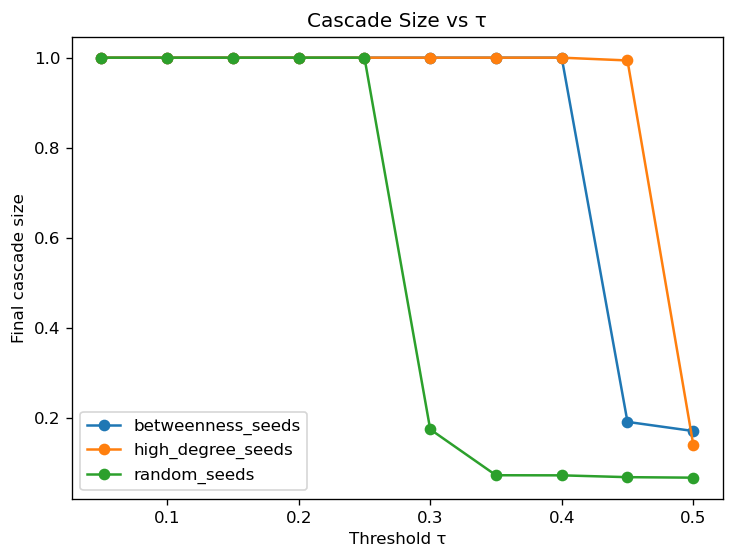

In [114]:
# Plots the τ-sweep
plt.figure(figsize=(7,5))
for name, group in df_tau.groupby("Strategy"):
    means = group.groupby("tau")["FinalAdoption"].mean()
    plt.plot(means.index, means.values, marker="o", label=name)
plt.xlabel("Threshold τ")
plt.ylabel("Final cascade size")
plt.title("Cascade Size vs τ")
plt.legend()
plt.savefig('Threshold_sweep.png', dpi=300, bbox_inches='tight')
plt.show()

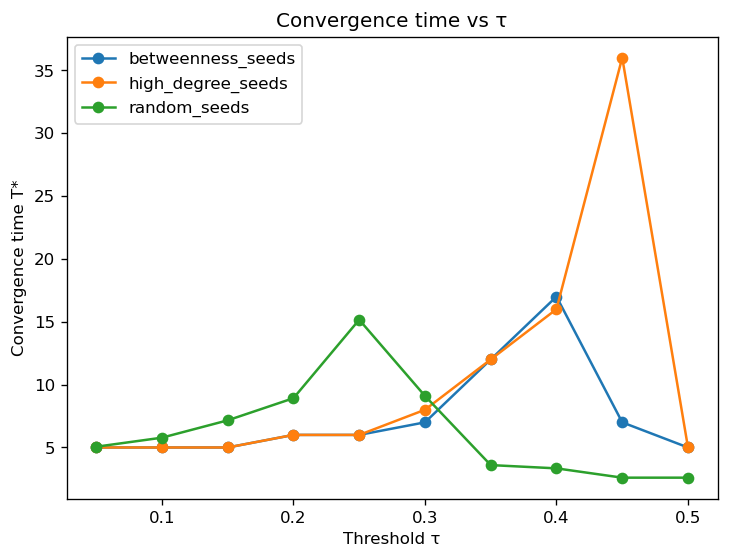

In [115]:
# plots the convergence time
plt.figure(figsize=(7,5))

for name, group in df_tau.groupby("Strategy"):
    group = group.sort_values("tau")

    if name == "Random":
        plt.errorbar(group["tau"], group["ConvergenceTime"],
                     yerr=group["StdConvergenceTime"], marker="o", capsize=3, label=name)
    else:
        plt.plot(group["tau"], group["ConvergenceTime"], marker="o", label=name)
    
plt.xlabel("Threshold τ")
plt.ylabel("Convergence time T*")
plt.title("Convergence time vs τ")
plt.legend()
plt.savefig('Convergence_time.png', dpi=300, bbox_inches='tight')
plt.show()

## Seed Fraction Sensitivity (f0-sweep)

In [116]:
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

def fraction_sweep(G, f0_values, tau_value, seed_function, max_steps=200, runs=50):
    """
    Evaluate diffusion outcomes across different initial seed fractions.

    Args:
        G (networkx.Graph): Undirected graph of email connections
        f0_values: Seed fractions
        tau_value: Threshold value
        seed_function: Seeding strategy 
        max_steps: Maximum number of steps in each simulation run
        runs (int): Number of Monte Carlo runs for random seeding

    Returns:
        pandas.DataFrame: Cascade size and convergence statistics for each seed fraction
    """
    
    dfs = []

    thresholds = {n: tau_value for n in G}


    for f0 in f0_values:
        final_sizes = []
        convergence_times = []

        B = max(1, round(f0 * G.number_of_nodes()))

        if seed_function == random_seeds:
            for _ in range(runs):
                seeds = random_seeds(G, B)
                       
    
                adopted, history = threshold_dynamics(
                    G, seeds, thresholds, max_steps=max_steps
                )
                final_sizes.append(final_adoption_fraction(adopted))
                convergence_times.append(len(history) - 1)
    
            df = pd.DataFrame({
            "Strategy": [seed_function.__name__],
            "f0": [f0],
            "B": [B],
            "FinalAdoption" : [np.mean(final_sizes)],
            "StdFinalAdoption" : [np.std(final_sizes)],
            "ConvergenceTime": [np.mean(convergence_times)]

            })

        else:
            seeds = seed_function(G, B)
            adopted, history = threshold_dynamics(
                    G, seeds, thresholds, max_steps=max_steps
                )
            
            df = pd.DataFrame({
            "Strategy": [seed_function.__name__],
            "f0": [f0],
            "B": [B],
            "FinalAdoption" : [final_adoption_fraction(adopted)],
            "ConvergenceTime": [len(history) - 1]
            })


        dfs.append(df)

    return pd.concat(dfs, ignore_index=True)
    

In [117]:
f0_values = [0.01, 0.02, 0.05, 0.10]
tau_value = 0.25

df_degree = fraction_sweep(G, f0_values, tau_value, high_degree_seeds)
    
df_betweenness = fraction_sweep(G, f0_values, tau_value, betweenness_seeds)
    
df_random = fraction_sweep(G, f0_values, tau_value, random_seeds)

df_fraction = pd.concat([df_degree, df_betweenness, df_random], ignore_index=True)

display(df_fraction)

,Strategy,f0,B,FinalAdoption,ConvergenceTime,StdFinalAdoption
0,high_degree_seeds,0.01,11,1.000000,13.00,NaN
1,high_degree_seeds,0.02,23,1.000000,9.00,NaN
2,high_degree_seeds,0.05,57,1.000000,6.00,NaN
3,high_degree_seeds,0.10,113,1.000000,6.00,NaN
4,betweenness_seeds,0.01,11,1.000000,15.00,NaN
5,betweenness_seeds,0.02,23,1.000000,9.00,NaN
6,betweenness_seeds,0.05,57,1.000000,6.00,NaN
7,betweenness_seeds,0.10,113,1.000000,5.00,NaN
8,random_seeds,0.01,11,0.042983,4.52,0.137175
9,random_seeds,0.02,23,0.204766,9.86,0.347461


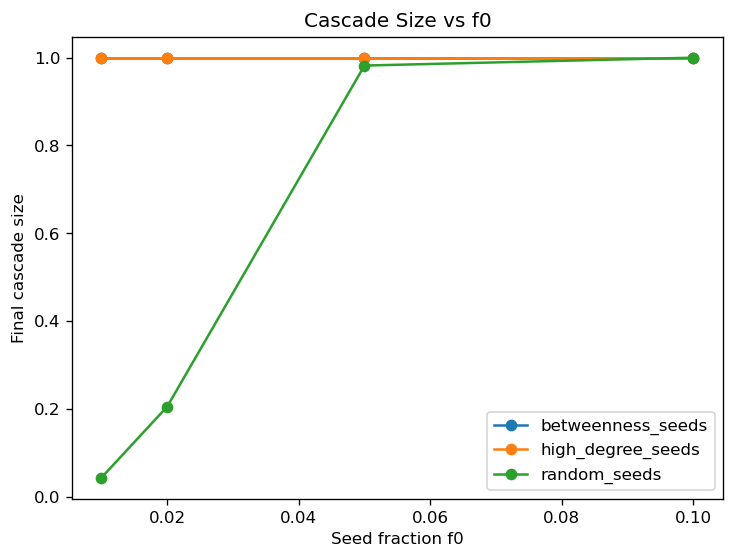

In [118]:
# Plots the f0-sweep
plt.figure(figsize=(7,5))
for name, group in df_fraction.groupby("Strategy"):
    means = group.groupby("f0")["FinalAdoption"].mean()
    plt.plot(means.index, means.values, marker="o", label=name)
plt.xlabel("Seed fraction f0")
plt.ylabel("Final cascade size")
plt.title("Cascade Size vs f0")
plt.legend()
plt.savefig('Fraction_sweep.png', dpi=300, bbox_inches='tight')
plt.show() 

In [119]:
csv_path = "tau_sweep_results.csv"
df_tau.to_csv(csv_path, index=False)
print("Saved:", csv_path)

csv_path = "fraction_sweep_results.csv"
df_tau.to_csv(csv_path, index=False)
print("Saved:", csv_path)

Saved: tau_sweep_results.csv
Saved: fraction_sweep_results.csv


In [120]:
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

def run_simulations(G, B, seed_function, tau=0.25, threshold_mode=None, runs=50, max_steps=200):
    """
    Runs repeated threshold contagion simulations and computes summary statistics.

    Args:
        G (networkx.Graph): Undirected graph of email connections
        B (int): Number of initial adopters
        seed_function: Seeding strategy 
        tau (float): Threshold value
        threshold_mode: Threshold distribution for heterogeneous thresholds
        runs (int): Number of Monte Carlo runs for random seeding
        max_steps: Maximum number of steps in each simulation run

    Returns:
        dict: Mean and standard deviation of cascade size, convergence time and adoption trajectory across runs
    """
    
    final_sizes = []
    convergence_times = []
    trajectories = []

    for _ in range(runs):
        seeds = seed_function(G, B)

        if threshold_mode is None:
            thresholds = {n: tau for n in G} # homogeneous
        else:
            thresholds = draw_thresholds(G, mode=threshold_mode) # heterogeneous

        adopted, history = threshold_dynamics(G, seeds, thresholds, max_steps=max_steps)

        final_sizes.append(final_adoption_fraction(adopted))
        convergence_times.append(len(history)-1)
        trajectories.append(history)
        
    max_len = max(len(t) for t in trajectories)
    padded = []
    for t in trajectories:
        padded.append(np.pad(t,(0,max_len - len(t)), mode="edge"))
    return{
        "Runs": runs,
        "MeanCascadeSize": np.mean(final_sizes),
        "StdCascadeSize": np.std(final_sizes),
        "MeanConvergenceTime": np.mean(convergence_times),
        "StdConvergenceTime": np.std(convergence_times),
        "MeanTrajectory": np.mean(padded, axis=0),
        "StdTrajectory": np.std(padded, axis=0),
    }
      

In [121]:
def strategy_comparison_table(degree_results, betweenness_results, random_results):
    """
    Creates summary table comparing the random, degree centrality and betweenness centrality seeding strategies.

    Args:
        degree_results (dict): Simulation results for degree centrality seeding
        betweenness_results (dict): Simulation results for betweenness centrality seeding
        random_results (dict): Simulation results for random seeding

    Returns:
        pandas.DataFrame: Table containing final cascade sizes and convergence times for each seeding strategy
    """
    
    table = pd.DataFrame({
        "Strategy": ["Random", "Degree", "Betweenness"],
        "Runs": [random_results["Runs"], degree_results["Runs"],
                 betweenness_results["Runs"]],
        "Final Cascade Size": [
            f"{random_results['MeanCascadeSize']:.3f} ± {random_results['StdCascadeSize']:.3f}",
            f"{degree_results['MeanCascadeSize']:.3f} ± {degree_results['StdCascadeSize']:.3f}",
            f"{betweenness_results['MeanCascadeSize']:.3f} ± {betweenness_results['StdCascadeSize']:.3f}",
        ],
        "Convergence Time": [
            f"{random_results['MeanConvergenceTime']:.3f} ± {random_results['StdConvergenceTime']:.3f}",
            f"{degree_results['MeanConvergenceTime']:.3f} ± {degree_results['StdConvergenceTime']:.3f}",
            f"{betweenness_results['MeanConvergenceTime']:.3f} ± {betweenness_results['StdConvergenceTime']:.3f}",
        ]
    })

    return table
        

,Strategy,Runs,Final Cascade Size,Convergence Time
0,Random,50,0.982 ± 0.125,14.740 ± 2.575
1,Degree,1,1.000 ± 0.000,6.000 ± 0.000
2,Betweenness,1,1.000 ± 0.000,6.000 ± 0.000


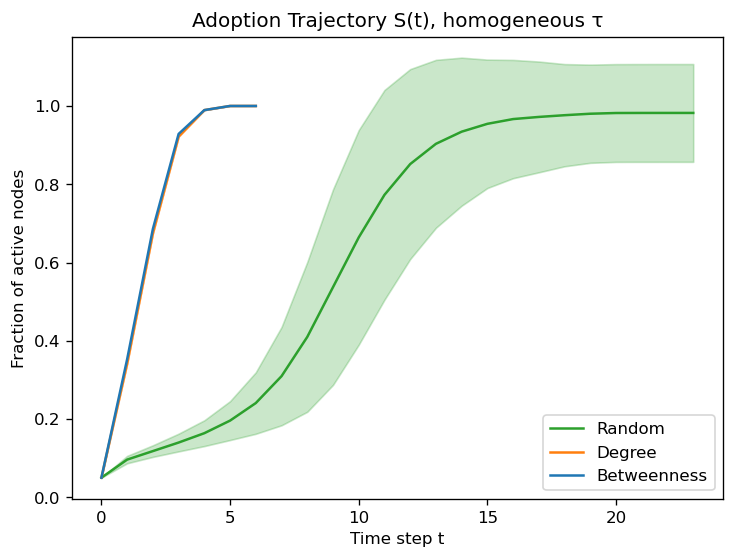

,Strategy,Runs,Final Cascade Size,Convergence Time
0,Random,50,0.333 ± 0.093,17.260 ± 4.987
1,Degree,50,0.626 ± 0.056,13.800 ± 2.653
2,Betweenness,50,0.630 ± 0.056,14.640 ± 3.404


<Figure size 720x480 with 0 Axes>

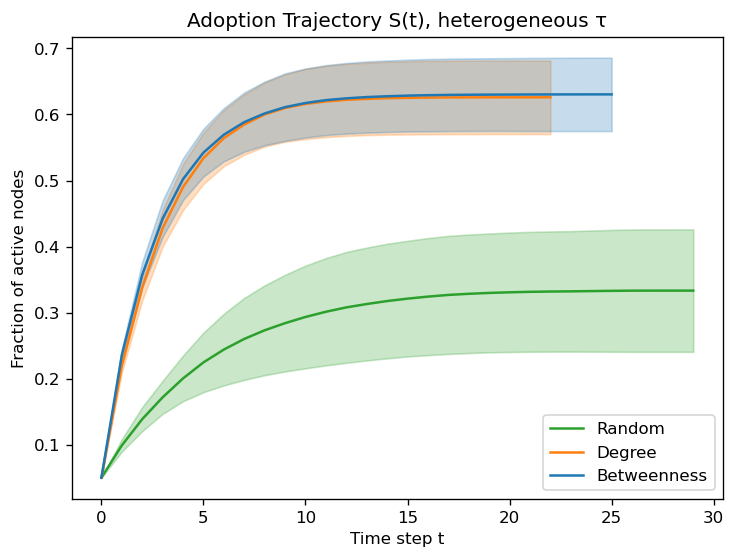

<Figure size 720x480 with 0 Axes>

In [122]:
def plot_trajectory(degree_results, betweenness_results, random_results, title):
    """
    Plots the mean adoption strategy for the random, degree centrality and betweenness centrality seeding strategies.

    Args:
        degree_results (dict): Simulation results for degree centrality seeding
        betweenness_results (dict): Simulation results for betweenness centrality seeding
        random_results (dict): Simulation results for random seeding
        title (str): Title of the plot
    """
    
    plt.figure(figsize=(7,5))
    for name, results, color in [("Random", random_results, "tab:green"),
                                 ("Degree", degree_results, "tab:orange"),
                                 ("Betweenness", betweenness_results, "tab:blue")]:
        mean = results["MeanTrajectory"]
        std = results["StdTrajectory"]
        t = np.arange(len(mean))
        plt.plot(t, mean, label=name, color=color)
        plt.fill_between(t, mean - std, mean + std, color=color, alpha=0.25)

    plt.xlabel("Time step t")
    plt.ylabel("Fraction of active nodes")
    plt.title(title)
    plt.legend()
    plt.show()

tau = 0.25

degree_results = run_simulations(G, B, high_degree_seeds, tau=tau, runs=1)
betweenness_results = run_simulations(G, B, betweenness_seeds, tau=tau, runs=1)
random_results = run_simulations(G, B, random_seeds, tau=tau, runs=50)

display(strategy_comparison_table(degree_results, betweenness_results, random_results))
plot_trajectory(degree_results, betweenness_results, random_results, f"Adoption Trajectory S(t), homogeneous τ")

degree_het = run_simulations(G, B, high_degree_seeds, threshold_mode="uniform", runs=50)
betweenness_het = run_simulations(G, B, betweenness_seeds, threshold_mode="uniform", runs=50)
random_het = run_simulations(G, B, random_seeds, threshold_mode="uniform", runs=50)

display(strategy_comparison_table(degree_het, betweenness_het, random_het))
plot_trajectory(degree_het, betweenness_het, random_het, f"Adoption Trajectory S(t), heterogeneous τ") 